In [11]:
import pandas as pd
import torch
import numpy as np
import random

In [20]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

In [12]:
train_data = pd.read_csv("data/rck_growth_train.csv")
test_data = pd.read_csv("data/rck_growth_test.csv")

In [22]:
grid_size = 100

#  column names
params_cols = ['alpha', 'delta', 'rho', 'theta', 'n', 'g', 'k0_initial', 'c0_initial']
t_grid_cols = [f't_grid_{i}' for i in range(grid_size)]
k_cols = [f'k_t{i}' for i in range(grid_size)]
c_cols = [f'c_t{i}' for i in range(grid_size)]

In [23]:
scaler_params = StandardScaler().fit(train_data[params_cols].values)
scaler_k = StandardScaler().fit(train_data[k_cols].values)
scaler_c = StandardScaler().fit(train_data[c_cols].values)

In [25]:
def prepare_fno_tensors(df, scaler_p, scaler_k_obj, scaler_c_obj):
    # Extract
    params = df[params_cols].values
    t_grid = df[t_grid_cols].values
    k_traj = df[k_cols].values
    c_traj = df[c_cols].values
    
    # Transform / Normalize
    params_scaled = scaler_p.transform(params)
    k_traj_scaled = scaler_k_obj.transform(k_traj)
    c_traj_scaled = scaler_c_obj.transform(c_traj)
    
    # Convert to Tensors
    params_torch = torch.tensor(params_scaled, dtype=torch.float32)
    t_grid_torch = torch.tensor(t_grid, dtype=torch.float32)
    k_traj_torch = torch.tensor(k_traj_scaled, dtype=torch.float32)
    c_traj_torch = torch.tensor(c_traj_scaled, dtype=torch.float32)
    
    # FNO format
    params_expanded = params_torch.unsqueeze(1).repeat(1, grid_size, 1) # (N, 100, 8)
    t_grid_expanded = t_grid_torch.unsqueeze(-1)                       # (N, 100, 1)
    
    # Combine channels
    X = torch.cat([t_grid_expanded, params_expanded], dim=-1)           # (N, 100, 9)
    Y = torch.stack([k_traj_torch, c_traj_torch], dim=-1)              # (N, 100, 2)
    
    return X, Y

In [27]:
X_train, Y_train = prepare_fno_tensors(train_data, scaler_params, scaler_k, scaler_c)
X_test, Y_test = prepare_fno_tensors(test_data, scaler_params, scaler_k, scaler_c)



In [28]:
train_dataset = TensorDataset(X_train, Y_train)
test_dataset = TensorDataset(X_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [31]:
import torch.nn as nn
from neuralop.models import FNO

FNO_MODES = (16,)  
HIDDEN_CHANNELS = 64

model = FNO(
    n_modes=FNO_MODES,
    in_channels=9,            # Time grid (1) + RCK parameters (8)
    out_channels=2,           # Capital trajectory (1) + Consumption trajectory (1)
    hidden_channels=HIDDEN_CHANNELS,
    projection_channel_ratio=2 
)

print(model)


FNO(
  (positional_embedding): GridEmbeddingND()
  (fno_blocks): FNOBlocks(
    (convs): ModuleList(
      (0-3): 4 x SpectralConv(
        (weight): DenseTensor(shape=torch.Size([64, 64, 9]), rank=None)
      )
    )
    (fno_skips): ModuleList(
      (0-3): 4 x Flattened1dConv(
        (conv): Conv1d(64, 64, kernel_size=(1,), stride=(1,), bias=False)
      )
    )
    (channel_mlp): ModuleList(
      (0-3): 4 x ChannelMLP(
        (fcs): ModuleList(
          (0): Conv1d(64, 32, kernel_size=(1,), stride=(1,))
          (1): Conv1d(32, 64, kernel_size=(1,), stride=(1,))
        )
      )
    )
    (channel_mlp_skips): ModuleList(
      (0-3): 4 x SoftGating()
    )
  )
  (lifting): ChannelMLP(
    (fcs): ModuleList(
      (0): Conv1d(10, 128, kernel_size=(1,), stride=(1,))
      (1): Conv1d(128, 64, kernel_size=(1,), stride=(1,))
    )
  )
  (projection): ChannelMLP(
    (fcs): ModuleList(
      (0): Conv1d(64, 128, kernel_size=(1,), stride=(1,))
      (1): Conv1d(128, 2, kernel_size=

In [34]:
import torch.optim as optim

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=5, factor=0.5)

num_epochs = 20

# Lists to track performance for plotting
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    # --- TRAINING PHASE ---
    model.train()
    train_loss = 0.0
    for X_batch, Y_batch in train_loader:
        X_batch = X_batch.permute(0, 2, 1)
        Y_batch = Y_batch.permute(0, 2, 1)
        
        optimizer.zero_grad()
        output = model(X_batch)
        loss = criterion(output, Y_batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * X_batch.size(0)
    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)
    
    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, Y_batch in test_loader:
            X_batch = X_batch.permute(0, 2, 1)
            Y_batch = Y_batch.permute(0, 2, 1)
            output = model(X_batch)
            loss = criterion(output, Y_batch)
            val_loss += loss.item() * X_batch.size(0)
    val_loss /= len(test_loader.dataset)
    val_losses.append(val_loss)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] -> Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")

Epoch [1/20] -> Train Loss: 0.074080 | Val Loss: 0.009731
Epoch [2/20] -> Train Loss: 0.005489 | Val Loss: 0.006196
Epoch [3/20] -> Train Loss: 0.003014 | Val Loss: 0.004362
Epoch [4/20] -> Train Loss: 0.002517 | Val Loss: 0.002547
Epoch [5/20] -> Train Loss: 0.002976 | Val Loss: 0.009635
Epoch [6/20] -> Train Loss: 0.003056 | Val Loss: 0.004942
Epoch [7/20] -> Train Loss: 0.006624 | Val Loss: 0.004481
Epoch [8/20] -> Train Loss: 0.003965 | Val Loss: 0.008701
Epoch [9/20] -> Train Loss: 0.002844 | Val Loss: 0.002181
Epoch [10/20] -> Train Loss: 0.002744 | Val Loss: 0.002214
Epoch [11/20] -> Train Loss: 0.003058 | Val Loss: 0.003145
Epoch [12/20] -> Train Loss: 0.002470 | Val Loss: 0.004001
Epoch [13/20] -> Train Loss: 0.002946 | Val Loss: 0.003729
Epoch [14/20] -> Train Loss: 0.003881 | Val Loss: 0.007007
Epoch [15/20] -> Train Loss: 0.006319 | Val Loss: 0.009026
Epoch [16/20] -> Train Loss: 0.004691 | Val Loss: 0.004154
Epoch [17/20] -> Train Loss: 0.001847 | Val Loss: 0.001728
Epoch 

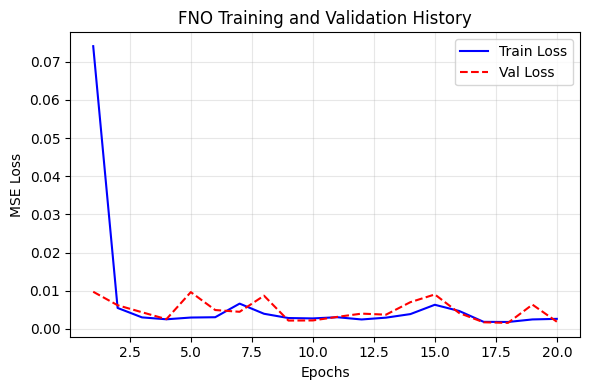

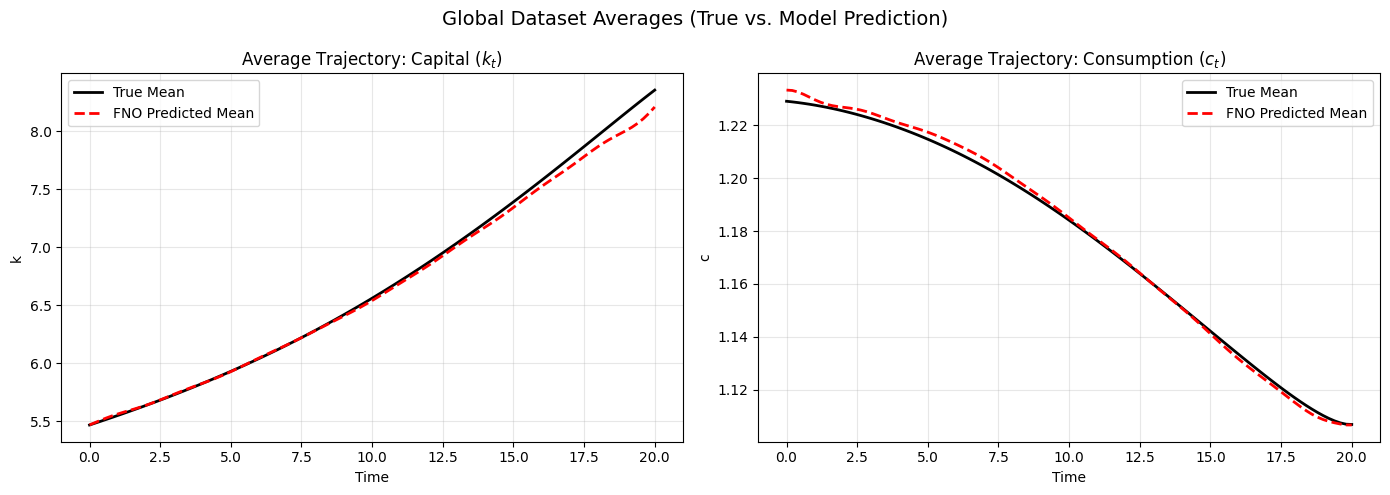

In [39]:
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for X_batch, Y_batch in test_loader:
        X_batch = X_batch.permute(0, 2, 1)
        output = model(X_batch) # Shape: [Batch, 2, 100]
        
        # Permute back to standard [Batch, Grid, Channels] for scaling ease
        all_preds.append(output.permute(0, 2, 1).numpy())
        all_targets.append(Y_batch.numpy())

all_preds = np.concatenate(all_preds, axis=0)     # Shape: (N_test, 100, 2)
all_targets = np.concatenate(all_targets, axis=0) # Shape: (N_test, 100, 2)

# 2. Invert scaling to view true physical values
# Channel 0 = Capital (k), Channel 1 = Consumption (c)
preds_k = scaler_k.inverse_transform(all_preds[:, :, 0])
preds_c = scaler_c.inverse_transform(all_preds[:, :, 1])

targets_k = scaler_k.inverse_transform(all_targets[:, :, 0])
targets_c = scaler_c.inverse_transform(all_targets[:, :, 1])

# Extract an actual time axis from your data (using first test sample row as reference)
time_axis = test_data[[f't_grid_{i}' for i in range(grid_size)]].iloc[0].values

# ----------------------------------------------------
# Plot 1: Loss History
# ----------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(range(1, num_epochs + 1), train_losses, label='Train Loss', color='blue')
plt.plot(range(1, num_epochs + 1), val_losses, label='Val Loss', color='red', linestyle='--')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('FNO Training and Validation History')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ----------------------------------------------------
# Plot 2: Average Output Function Profiles
# ----------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average Capital profile
axes[0].plot(time_axis, targets_k.mean(axis=0), 'k-', linewidth=2, label='True Mean')
axes[0].plot(time_axis, preds_k.mean(axis=0), 'r--', linewidth=2, label='FNO Predicted Mean')
axes[0].set_title('Average Trajectory: Capital ($k_t$)')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('k')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Average Consumption profile
axes[1].plot(time_axis, targets_c.mean(axis=0), 'k-', linewidth=2, label='True Mean')
axes[1].plot(time_axis, preds_c.mean(axis=0), 'r--', linewidth=2, label='FNO Predicted Mean')
axes[1].set_title('Average Trajectory: Consumption ($c_t$)')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('c')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Global Dataset Averages (True vs. Model Prediction)', fontsize=14)
plt.tight_layout()
plt.show()

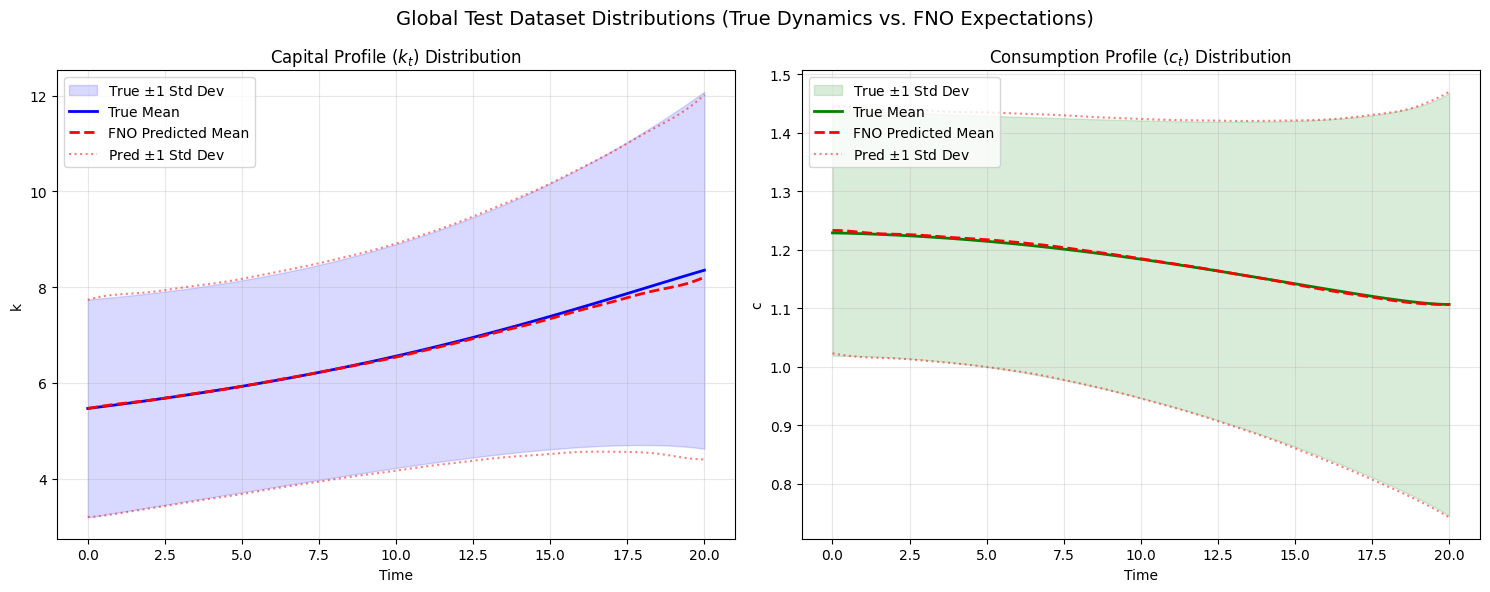

In [41]:
import matplotlib.pyplot as plt
import numpy as np

# ----------------------------------------------------
# 1. Compute Descriptive Statistics (Mean & Std)
# ----------------------------------------------------
# Calculate means across all test samples
mean_target_k = targets_k.mean(axis=0)
mean_pred_k   = preds_k.mean(axis=0)

mean_target_c = targets_c.mean(axis=0)
mean_pred_c   = preds_c.mean(axis=0)

# Calculate standard deviations across all test samples
std_target_k  = targets_k.std(axis=0)
std_pred_k    = preds_k.std(axis=0)

std_target_c  = targets_c.std(axis=0)
std_pred_c    = preds_c.std(axis=0)

# ----------------------------------------------------
# 2. Plot Average Trajectories with Variance Bands
# ----------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- LEFT PLOT: Capital (k_t) ---
# True distribution variance band
axes[0].fill_between(time_axis, mean_target_k - std_target_k, mean_target_k + std_target_k, 
                     color='blue', alpha=0.15, label='True $\pm$1 Std Dev')
axes[0].plot(time_axis, mean_target_k, color='blue', linewidth=2, label='True Mean')

# FNO predicted variance lines
axes[0].plot(time_axis, mean_pred_k, color='red', linestyle='--', linewidth=2, label='FNO Predicted Mean')
axes[0].plot(time_axis, mean_pred_k + std_pred_k, color='red', linestyle=':', alpha=0.5)
axes[0].plot(time_axis, mean_pred_k - std_pred_k, color='red', linestyle=':', alpha=0.5, label='Pred $\pm$1 Std Dev')

axes[0].set_title('Capital Profile ($k_t$) Distribution')
axes[0].set_xlabel('Time')
axes[0].set_ylabel('k')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)


# --- RIGHT PLOT: Consumption (c_t) ---
# True distribution variance band
axes[1].fill_between(time_axis, mean_target_c - std_target_c, mean_target_c + std_target_c, 
                     color='green', alpha=0.15, label='True $\pm$1 Std Dev')
axes[1].plot(time_axis, mean_target_c, color='green', linewidth=2, label='True Mean')

# FNO predicted variance lines
axes[1].plot(time_axis, mean_pred_c, color='red', linestyle='--', linewidth=2, label='FNO Predicted Mean')
axes[1].plot(time_axis, mean_pred_c + std_pred_c, color='red', linestyle=':', alpha=0.5)
axes[1].plot(time_axis, mean_pred_c - std_pred_c, color='red', linestyle=':', alpha=0.5, label='Pred $\pm$1 Std Dev')

axes[1].set_title('Consumption Profile ($c_t$) Distribution')
axes[1].set_xlabel('Time')
axes[1].set_ylabel('c')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Global Test Dataset Distributions (True Dynamics vs. FNO Expectations)', fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

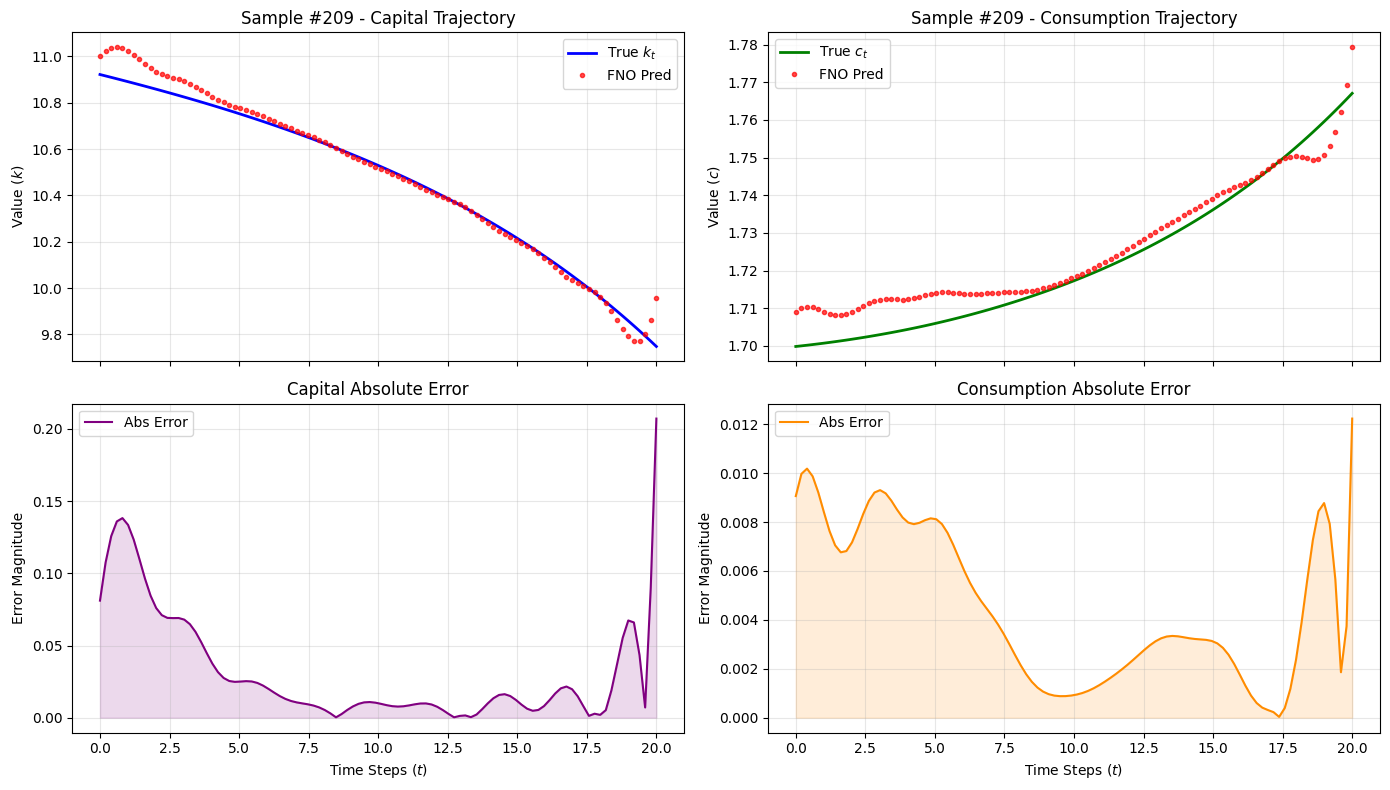

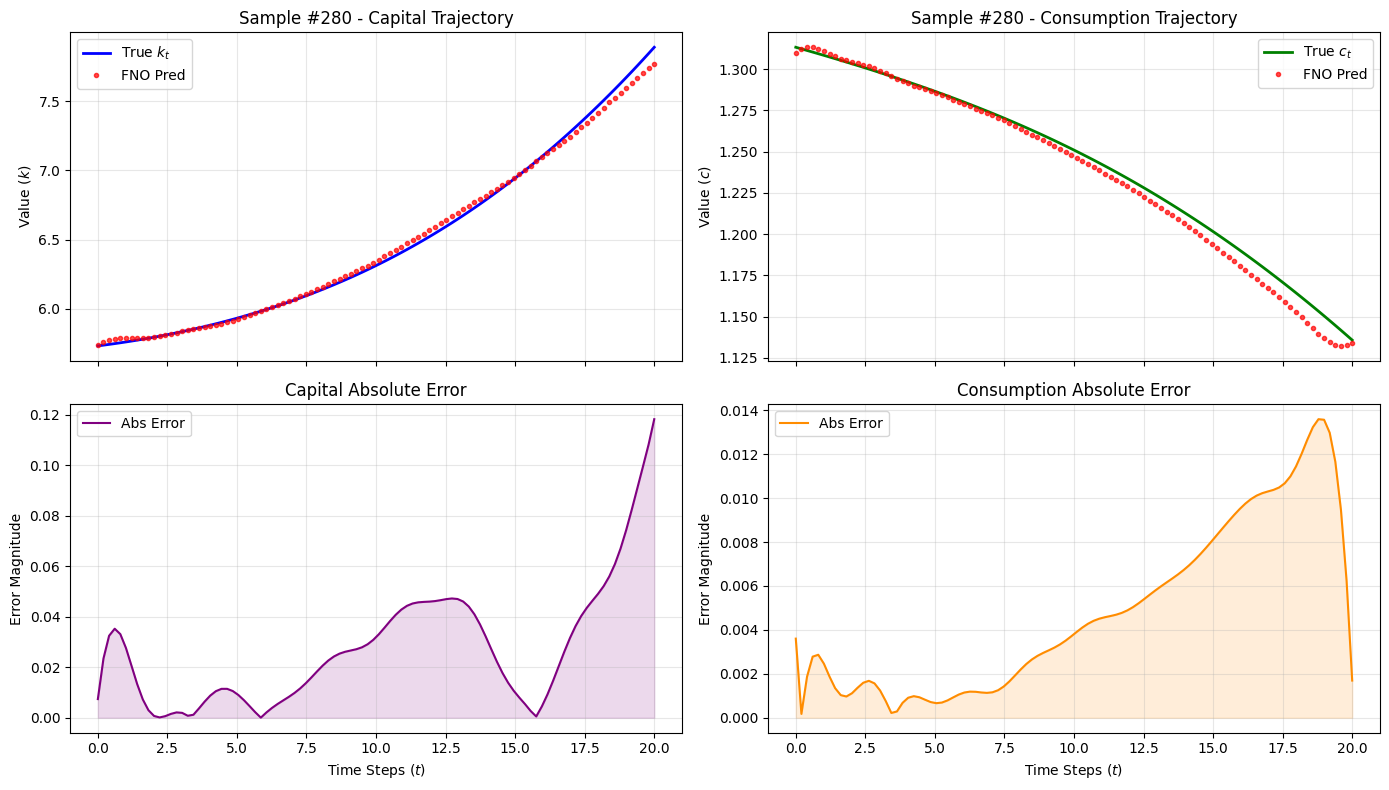

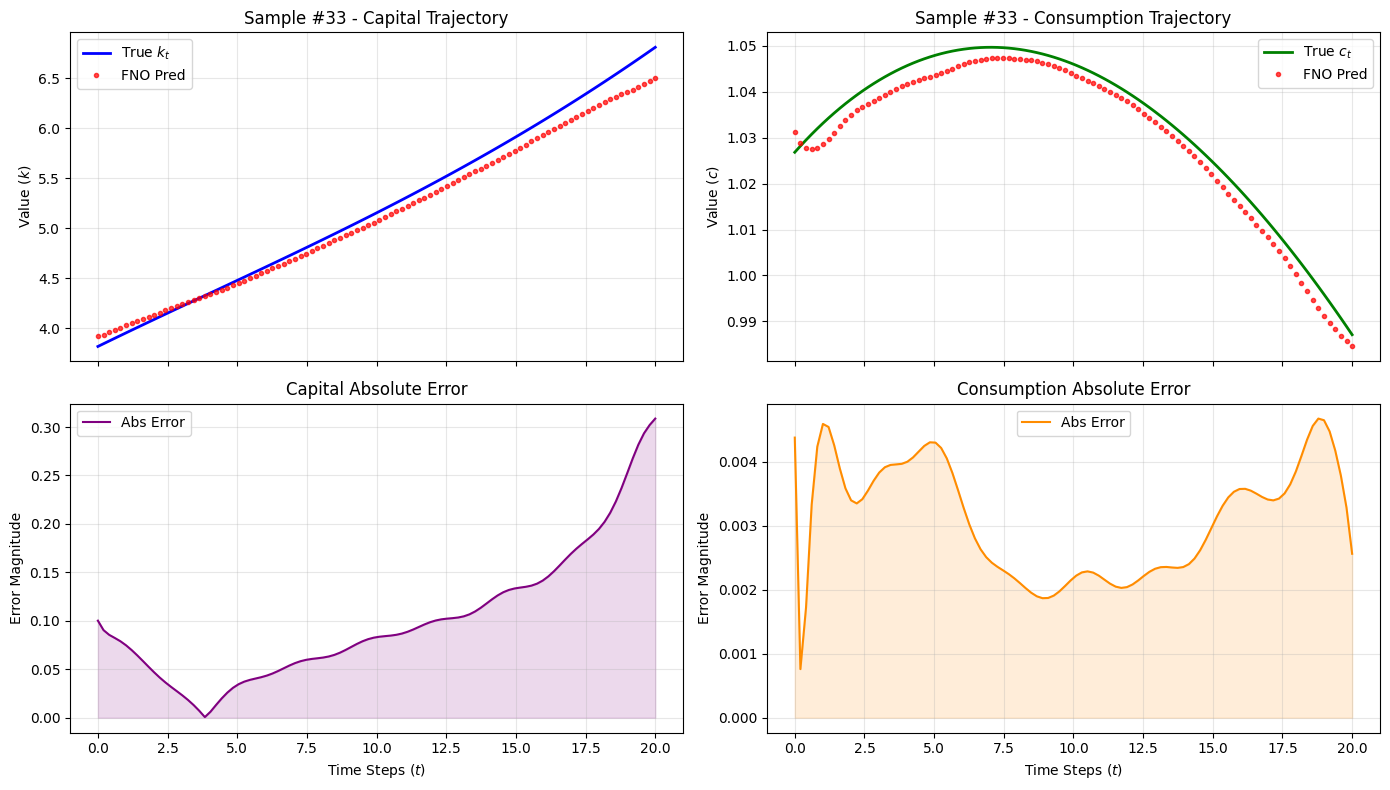

In [38]:
import matplotlib.pyplot as plt
import numpy as np

# ----------------------------------------------------
# 1. Gather Predictions and Targets
# ----------------------------------------------------
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for X_batch, Y_batch in test_loader:
        X_batch = X_batch.permute(0, 2, 1)
        output = model(X_batch)
        all_preds.append(output.permute(0, 2, 1).numpy())
        all_targets.append(Y_batch.numpy())

all_preds = np.concatenate(all_preds, axis=0)     
all_targets = np.concatenate(all_targets, axis=0) 

# Revert normalizations to maintain real economic scales
preds_k = scaler_k.inverse_transform(all_preds[:, :, 0])
preds_c = scaler_c.inverse_transform(all_preds[:, :, 1])

targets_k = scaler_k.inverse_transform(all_targets[:, :, 0])
targets_c = scaler_c.inverse_transform(all_targets[:, :, 1])

# Extract time coordinates
time_axis = test_data[[f't_grid_{i}' for i in range(grid_size)]].iloc[0].values

# Compute Absolute Error
abs_error_k = np.abs(targets_k - preds_k)
abs_error_c = np.abs(targets_c - preds_c)

# ----------------------------------------------------
# 2. Plot Samples (Separated Curves and Error Subplots)
# ----------------------------------------------------
np.random.seed(42)  # Change or remove to view different test trajectories
random_indices = np.random.choice(len(all_preds), size=3, replace=False)

for sample_idx in random_indices:
    # Create a clean, separate figure for each selected trajectory sample
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    
    # ------------------------------------------------
    # LEFT PANEL: Capital (k_t)
    # ------------------------------------------------
    # Top Left: Profiles
    axes[0, 0].plot(time_axis, targets_k[sample_idx], 'b-', linewidth=2, label='True $k_t$')
    axes[0, 0].plot(time_axis, preds_k[sample_idx], 'ro', markersize=3, alpha=0.7, label='FNO Pred')
    axes[0, 0].set_title(f'Sample #{sample_idx} - Capital Trajectory')
    axes[0, 0].set_ylabel('Value ($k$)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Bottom Left: Absolute Error
    axes[1, 0].fill_between(time_axis, abs_error_k[sample_idx], color='purple', alpha=0.15)
    axes[1, 0].plot(time_axis, abs_error_k[sample_idx], color='purple', linewidth=1.5, label='Abs Error')
    axes[1, 0].set_title('Capital Absolute Error')
    axes[1, 0].set_xlabel('Time Steps ($t$)')
    axes[1, 0].set_ylabel('Error Magnitude')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # ------------------------------------------------
    # RIGHT PANEL: Consumption (c_t)
    # ------------------------------------------------
    # Top Right: Profiles
    axes[0, 1].plot(time_axis, targets_c[sample_idx], 'g-', linewidth=2, label='True $c_t$')
    axes[0, 1].plot(time_axis, preds_c[sample_idx], 'ro', markersize=3, alpha=0.7, label='FNO Pred')
    axes[0, 1].set_title(f'Sample #{sample_idx} - Consumption Trajectory')
    axes[0, 1].set_ylabel('Value ($c$)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Bottom Right: Absolute Error
    axes[1, 1].fill_between(time_axis, abs_error_c[sample_idx], color='darkorange', alpha=0.15)
    axes[1, 1].plot(time_axis, abs_error_c[sample_idx], color='darkorange', linewidth=1.5, label='Abs Error')
    axes[1, 1].set_title('Consumption Absolute Error')
    axes[1, 1].set_xlabel('Time Steps ($t$)')
    axes[1, 1].set_ylabel('Error Magnitude')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()